# AISE 4010 Project - Group 2

Abdullayev, Jahangir

Heddle, Bryan William

Linders, Matthew Donald

Renno, Nimer

In [3]:
# Install missing packages in the current notebook kernel's environment.
import importlib.util
import subprocess
import sys

# TODO: remove any unused packages from the list below at end
packages = ["pandas", "matplotlib", "seaborn", "plotly"]
missing = [package for package in packages if importlib.util.find_spec(package) is None]

if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

In [ ]:
# Import dataset
import pandas as pd

dataset_url = "https://raw.githubusercontent.com/laiguokun/multivariate-time-series-data/master/traffic/traffic.txt.gz"
# Download into memory and decompress directly; no local dataset file is needed.
df = pd.read_csv(dataset_url, compression="gzip", header=None)

print(f"Loaded {df.shape[0]:,} time steps and {df.shape[1]:,} traffic sensors.")
df.head()

Loaded 17,544 time steps and 862 traffic sensors.


,0,1,2,3,4,5,6,7,8,9,...,852,853,854,855,856,857,858,859,860,861
0,0.0048,0.0146,0.0289,0.0142,0.0064,0.0232,0.0162,0.0242,0.0341,0.0375,...,0.0051,0.0051,0.0074,0.0079,0.0051,0.0051,0.0339,0.0051,0.0100,0.0121
1,0.0072,0.0148,0.0350,0.0174,0.0084,0.0240,0.0201,0.0338,0.0434,0.0381,...,0.0036,0.0036,0.0107,0.0058,0.0036,0.0036,0.0348,0.0036,0.0087,0.0136
2,0.0040,0.0101,0.0267,0.0124,0.0049,0.0170,0.0127,0.0255,0.0332,0.0309,...,0.0030,0.0030,0.0043,0.0050,0.0030,0.0030,0.0327,0.0030,0.0061,0.0107
3,0.0039,0.0060,0.0218,0.0090,0.0029,0.0118,0.0088,0.0163,0.0211,0.0199,...,0.0033,0.0033,0.0019,0.0052,0.0033,0.0033,0.0292,0.0033,0.0040,0.0071
4,0.0042,0.0055,0.0191,0.0082,0.0024,0.0095,0.0064,0.0087,0.0144,0.0226,...,0.0049,0.0049,0.0011,0.0071,0.0049,0.0049,0.0264,0.0049,0.0040,0.0039


## Understanding the Dataset

This dataset records **hourly road occupancy at 862 traffic sensors on San Francisco Bay Area freeways**. Occupancy measures the fraction of time a sensor detects a vehicle: `0.05` means 5% occupancy, rather than a vehicle count or speed.

Each **row** represents one hourly observation, ordered through time. Each **column**, numbered `0`–`861`, represents a different sensor. The dataset contains **17,544 observations**. This file does not include timestamps, sensor names, or locations, so its row and column numbers are positional identifiers.

[Dataset source and description](https://github.com/laiguokun/multivariate-time-series-data#traffic-usage)

<class 'pandas.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Columns: 862 entries, 0 to 861
dtypes: float64(862)
memory usage: 115.4 MB
Missing values: 0


,0,1,2,3,4
count,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000
mean,0.049324,0.046016,0.105870,0.056633,0.026812
std,0.062469,0.048398,0.082205,0.036746,0.035872
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.008900,0.018100,0.035600,0.026800,0.007875
50%,0.046300,0.036800,0.081000,0.060000,0.019000
75%,0.059900,0.053700,0.175500,0.074700,0.024300
max,0.474700,0.450000,0.420100,0.494700,0.406900


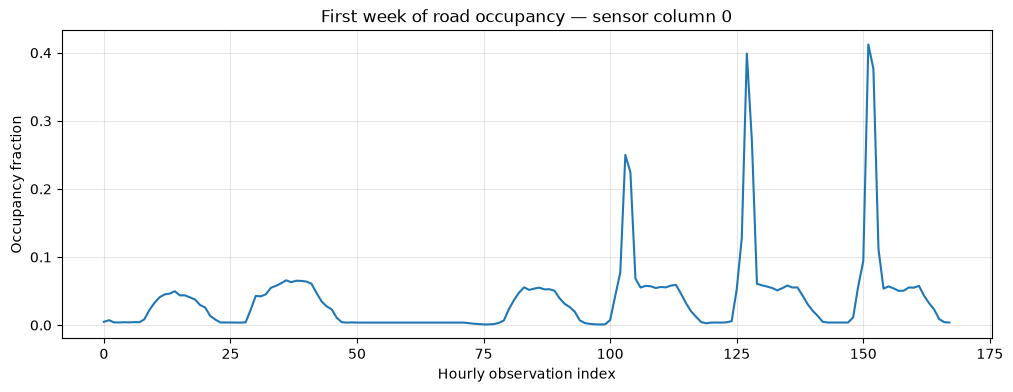

In [5]:
import matplotlib.pyplot as plt

df.info()
print("Missing values:", df.isna().sum().sum())
display(df.iloc[:, :5].describe())

# First 168 hourly observations = approximately one week.
# Column 0 is an illustration, not a selected forecasting target.
df.iloc[:168, 0].plot(figsize=(12, 4))
plt.title("First week of road occupancy — sensor column 0")
plt.xlabel("Hourly observation index")
plt.ylabel("Occupancy fraction")
plt.grid(alpha=0.3)
plt.show()